In [50]:
######### DATASET 1: insuficiencia renal cronica
## com boxpot, feature importance e PCA


#1. CARREGAMENTO E INSPEÇÃO DE DADOS

In [51]:
##testes para rodar tudo certo
import sys
print(sys.executable)
print(sys.version)

import sklearn
print("sklearn OK, versão:", sklearn.__version__)

/home/jlemos/ml_env/bin/python
3.13.2 | packaged by Anaconda, Inc. | (main, Feb  6 2025, 18:56:02) [GCC 11.2.0]
sklearn OK, versão: 1.8.0


In [52]:
import pandas as pd
import matplotlib.pyplot as plt
print("pandas OK:", pd.__version__)
print("matplotlib OK:", plt.matplotlib.__version__)

pandas OK: 3.0.3
matplotlib OK: 3.10.8


In [53]:
# Importa bibliotecas para trabalhar com arquivos zip e pastas
import zipfile
import os

# Caminho do arquivo zip
# Como o notebook já está dentro da pasta ML, não precisa colocar "ML/" antes
zip_path = "archive.zip"

# Extrai os arquivos do zip para a pasta dataset
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("dataset")

# Mostra os arquivos extraídos
print(os.listdir("dataset"))

['Dataset_insuficiencia_renal_crnica.csv', '.ipynb_checkpoints']


In [54]:
csv_path = None

for pasta_atual, subpastas, arquivos in os.walk("."):
    if ".ipynb_checkpoints" in pasta_atual:
        continue
    
    for arquivo in arquivos:
        if arquivo.endswith(".csv"):
            csv_path = os.path.join(pasta_atual, arquivo)

print("Arquivo encontrado:", csv_path)

df = pd.read_csv(csv_path)
df.head()

Arquivo encontrado: ./dataset/Dataset_insuficiencia_renal_crnica.csv


,Identificación del paciente,Edad,Presión arterial,Gravedad específica de la orina,Albúmina en orina,Azúcar en orina,Glóbulos rojos,Células de pus,Grupos de células de pus,Bacterias,...,Urea en sangre,Creatinina sérica,Sodio en sangre,Potasio en sangre,Hemoglobina,Volumen corpuscular empaquetado,Recuento de glóbulos blancos,Recuento de glóbulos rojos,Apetito,Insuficiencia renal crónica
0,0,48,178,1010.0,2.0,2,anormal,anormal,presente,presente,...,195.0,9.08,124.0,6.0,8.0,25.0,11319,3.8,bajo,si
1,1,7,138,1014.0,1.0,4,anormal,anormal,presente,presente,...,111.0,7.88,133.0,6.8,11.0,27.0,11018,2.9,bajo,si
2,2,62,165,1014.0,2.0,5,anormal,anormal,presente,presente,...,149.0,12.89,130.0,6.0,8.0,27.0,5479,4.4,bajo,si
3,3,48,141,1007.0,4.0,4,anormal,anormal,presente,presente,...,98.0,5.02,133.0,5.8,11.0,35.0,7817,3.2,bajo,si
4,4,51,175,1015.0,4.0,5,anormal,anormal,presente,presente,...,152.0,7.32,132.0,6.8,9.0,30.0,3055,3.9,bajo,si


In [55]:
df.info()

#mostra informacoes gerais do dataset
#15051 linhas (pacientes) e 21 columas (variaveis)
# coluna 20 = y
# outras colunas = x (variaveis de entrada)

<class 'pandas.DataFrame'>
RangeIndex: 15051 entries, 0 to 15050
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Identificación del paciente      15051 non-null  int64  
 1   Edad                             15051 non-null  int64  
 2   Presión arterial                 15051 non-null  int64  
 3   Gravedad específica de la orina  15051 non-null  float64
 4   Albúmina en orina                15051 non-null  float64
 5   Azúcar en orina                  15051 non-null  int64  
 6   Glóbulos rojos                   15051 non-null  str    
 7   Células de pus                   15051 non-null  str    
 8   Grupos de células de pus         15042 non-null  str    
 9   Bacterias                        15045 non-null  str    
 10  Glucosa en sangre aleatoria      15051 non-null  int64  
 11  Urea en sangre                   15051 non-null  float64
 12  Creatinina sérica            

In [56]:
#2. LIMPEZA E PRÉ-PROCESSAMENTO

#x = características clínicas dos pacientes
#y = classe que o modelo deve prever
#  no = 0
#  si = 1

#distribuicao das classes
# Classe 0: 7678 amostras
# Classe 1: 7346 amostras

In [57]:
#remove linhas com valores faltantes
df = df.dropna()

#remove a coluna de identificação do paciente,
# pois ela representa apenas um código/ID e não deve ser usada na predição
df = df.drop(columns=["Identificación del paciente"], errors="ignore")

#mostra o tamanho final do dataset
print("Formato apos limpeza do dataset:", df.shape)

#mostra as informacoes do dataset limpo
df.info()

Formato apos limpeza do dataset: (15024, 20)
<class 'pandas.DataFrame'>
Index: 15024 entries, 0 to 15050
Data columns (total 20 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Edad                             15024 non-null  int64  
 1   Presión arterial                 15024 non-null  int64  
 2   Gravedad específica de la orina  15024 non-null  float64
 3   Albúmina en orina                15024 non-null  float64
 4   Azúcar en orina                  15024 non-null  int64  
 5   Glóbulos rojos                   15024 non-null  str    
 6   Células de pus                   15024 non-null  str    
 7   Grupos de células de pus         15024 non-null  str    
 8   Bacterias                        15024 non-null  str    
 9   Glucosa en sangre aleatoria      15024 non-null  int64  
 10  Urea en sangre                   15024 non-null  float64
 11  Creatinina sérica                15024 non-null  fl

In [58]:
#separacao das variaveis preditoras (colunas usadas para fazer a previsao)
# separa todas colunas, exceto a "Insuficiencia renal crónica"
x = df.drop(
    ["Insuficiencia renal crónica"], axis=1
)

#separa a variavel de saida (ultima coluna, a que se quer prever)
y = df["Insuficiencia renal crónica"]

In [59]:
#para padronizar as respostas em y como 0 (nao) e 1 (sim)

#padroniza os textos da variavel-alvo:
# remove espaços e deixa tudo minúsculo
y = y.astype(str).str.strip().str.lower()

# Converte as classes para números
# no = 0 representa ausência da doença
# si = 1 representa presença da doença
y = y.map({
    "no": 0,
    "si": 1
})

# Confere a quantidade de amostras em cada classe
y.value_counts(dropna=False)

Insuficiencia renal crónica
0    7678
1    7346
Name: count, dtype: int64

In [60]:
#infos de X para verificar se ha colunas de texto (Dtype: object)
# e transformar em numeros
x.info()

<class 'pandas.DataFrame'>
Index: 15024 entries, 0 to 15050
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Edad                             15024 non-null  int64  
 1   Presión arterial                 15024 non-null  int64  
 2   Gravedad específica de la orina  15024 non-null  float64
 3   Albúmina en orina                15024 non-null  float64
 4   Azúcar en orina                  15024 non-null  int64  
 5   Glóbulos rojos                   15024 non-null  str    
 6   Células de pus                   15024 non-null  str    
 7   Grupos de células de pus         15024 non-null  str    
 8   Bacterias                        15024 non-null  str    
 9   Glucosa en sangre aleatoria      15024 non-null  int64  
 10  Urea en sangre                   15024 non-null  float64
 11  Creatinina sérica                15024 non-null  float64
 12  Sodio en sangre                  1

In [61]:
#converte as colunas de X de texto em numeros

# drop_first = True evita criar colunas repetitivas demais
#  Por exemplo, se uma variável só tem duas categorias, ele cria apenas uma coluna, porque a outra categoria fica implícita.
x = pd.get_dummies(x, drop_first=True)

#garante que todas coluans estejam em formato numerico
x = x.astype(float)

#cnfere novamente os tipos das colunas apos a conversão
x.info()

<class 'pandas.DataFrame'>
Index: 15024 entries, 0 to 15050
Data columns (total 19 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Edad                               15024 non-null  float64
 1   Presión arterial                   15024 non-null  float64
 2   Gravedad específica de la orina    15024 non-null  float64
 3   Albúmina en orina                  15024 non-null  float64
 4   Azúcar en orina                    15024 non-null  float64
 5   Glucosa en sangre aleatoria        15024 non-null  float64
 6   Urea en sangre                     15024 non-null  float64
 7   Creatinina sérica                  15024 non-null  float64
 8   Sodio en sangre                    15024 non-null  float64
 9   Potasio en sangre                  15024 non-null  float64
 10  Hemoglobina                        15024 non-null  float64
 11  Volumen corpuscular empaquetado    15024 non-null  float64
 12  Recuen

In [62]:
#importa o modelo/algoritmo random forest
from sklearn.ensemble import RandomForestClassifier
#importa metricas de avaliacao do modelo
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

#confirmar importacao das bibliotecas
print("sklearn importado com sucesso! :)")

sklearn importado com sucesso! :)


In [63]:
#importa bibliotecas para configurar caminhos do ambiente
import sys
import os

#adiciona pasta local de pactotes ao caminho de busca do python
# (pq antes tava dando erro para importar o sklearn)
sys.path.insert(0, os.path.abspath("../pacotes_python"))

In [64]:
#importa função para separar os dados em treino, teste e validação
from sklearn.model_selection import train_test_split

#importa algoritmos de classificação
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

#importa métricas de avaliação
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

#importa ferramentas para validação cruzada e tuning
from sklearn.model_selection import cross_val_score, GridSearchCV

#importa biblioteca para gráficos
import matplotlib.pyplot as plt

print("bibliotecas importadas com sucesso!")

bibliotecas importadas com sucesso!


In [65]:
#reconstrói x e y a partir do df atual,
# pq ainda apareciam valores NaN (erro na separacao dos dados)

# Nome da coluna alvo
coluna_alvo = "Insuficiencia renal crónica"

# Cria uma cópia do df para modelagem
df_modelo = df.copy()

# Padroniza a coluna alvo: remove espaços e deixa tudo minúsculo
df_modelo[coluna_alvo] = df_modelo[coluna_alvo].astype(str).str.strip().str.lower()

# Mantém apenas as linhas em que a classe é "no" ou "si"
# Isso remove qualquer valor estranho que não consiga virar 0 ou 1
df_modelo = df_modelo[df_modelo[coluna_alvo].isin(["no", "si"])]

# Separa as variáveis preditoras
x = df_modelo.drop(columns=[coluna_alvo, "Identificación del paciente"], errors="ignore")

# Separa a variável-alvo e transforma em 0 e 1
y = df_modelo[coluna_alvo].map({
    "no": 0,
    "si": 1
})

# Converte y para inteiro
y = y.astype(int)

# Converte colunas categóricas/texto de x em colunas numéricas
x = pd.get_dummies(x, drop_first=True)

# Garante que x esteja todo em formato numérico
x = x.astype(float)

# Reseta os índices para x e y ficarem alinhados
x = x.reset_index(drop=True)
y = y.reset_index(drop=True)

# Conferências finais
print("Formato de x:", x.shape)
print("Formato de y:", y.shape)
print("\nClasses em y:")
print(y.value_counts(dropna=False))

print("\nValores faltantes em y:", y.isnull().sum())
print("Valores faltantes em x:", x.isnull().sum().sum())

Formato de x: (15024, 19)
Formato de y: (15024,)

Classes em y:
Insuficiencia renal crónica
0    7678
1    7346
Name: count, dtype: int64

Valores faltantes em y: 0
Valores faltantes em x: 0


In [66]:
# Remove linhas que ainda tenham valores faltantes em x
# e mantém y alinhado com as mesmas linhas

linhas_validas = x.notnull().all(axis=1)

x = x.loc[linhas_validas]
y = y.loc[linhas_validas]

# Reseta os índices para evitar desalinhamento
x = x.reset_index(drop=True)
y = y.reset_index(drop=True)

# Confere se ainda existem valores faltantes
print("Valores faltantes em x:", x.isnull().sum().sum())
print("Valores faltantes em y:", y.isnull().sum())

print("Formato de x:", x.shape)
print("Formato de y:", y.shape)

print("\nDistribuição das classes:")
print(y.value_counts())

Valores faltantes em x: 0
Valores faltantes em y: 0
Formato de x: (15024, 19)
Formato de y: (15024,)

Distribuição das classes:
Insuficiencia renal crónica
0    7678
1    7346
Name: count, dtype: int64


In [67]:
# Remove linhas que ainda possuem valores faltantes em x
# e remove as mesmas linhas em y para manter x e y alinhados

linhas_sem_nan = x.notna().all(axis=1)

x = x.loc[linhas_sem_nan]
y = y.loc[linhas_sem_nan]

# Reseta os índices para evitar desalinhamento entre x e y
x = x.reset_index(drop=True)
y = y.reset_index(drop=True)

# Confere se a correção funcionou
print("Valores faltantes em x:", x.isnull().sum().sum())
print("Valores faltantes em y:", y.isnull().sum())

print("Formato de x:", x.shape)
print("Formato de y:", y.shape)

print("\nDistribuição das classes:")
print(y.value_counts())

Valores faltantes em x: 0
Valores faltantes em y: 0
Formato de x: (15024, 19)
Formato de y: (15024,)

Distribuição das classes:
Insuficiencia renal crónica
0    7678
1    7346
Name: count, dtype: int64


In [68]:
#3. SEPARAÇÃO DE DADOS

#15% separado para validacao final
#outros 85% divididos em treino e teste
#  Treino: 10216 amostras
#    usado para ajsutar os modelos
#  Teste: 2554 amostras
#    usado para comparar o desempenho inicial
#  Validação final: 2254 amostras
#    mantido separado para uma avaliação mais independente

#separa 15% do dataset para validação final
x_temp, x_validacao, y_temp, y_validacao = train_test_split(
    x,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

#separa o restante dos dados em treino e teste
# x_temp e y_temp representam os 85% restantes do dataset
x_train, x_test, y_train, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.20,
    random_state=42,
    stratify=y_temp
)

#mostra o tamanho de cada conjunto
print("Treino:", x_train.shape)
print("Teste:", x_test.shape)
print("Validação:", x_validacao.shape)

Treino: (10216, 19)
Teste: (2554, 19)
Validação: (2254, 19)


In [69]:
#4. MODELOS TREINADOS
# regressão logistica:
#   modelo mais simples e interpretável para classificação binária
#   StandardScaler: para padronizacao de variaveis (pois o modelo eh sensivel a escala de dados)
# random forest:
#   modelo baseado em múltiplas árvores de decisão, capaz de capturar relações não lineares entre as variáveis

# Importa ferramentas para padronização e pipeline
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Cria os modelos que serão comparados
# Regressão Logística usa StandardScaler porque é sensível à escala dos dados
# Random Forest não precisa de padronização obrigatoriamente
modelos = {
    "Regressão Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=5000, random_state=42))
    ]),
    
    "Random Forest": RandomForestClassifier(random_state=42)
}

# Lista para armazenar os resultados de cada modelo
resultados = []

# Treina e avalia cada modelo
for nome, modelo in modelos.items():
    
    # Treina o modelo com o conjunto de treino
    modelo.fit(x_train, y_train)
    
    # Faz previsões no treino
    y_pred_train = modelo.predict(x_train)
    
    # Faz previsões no teste
    y_pred_test = modelo.predict(x_test)
    
    # Calcula acurácia no treino
    acc_train = accuracy_score(y_train, y_pred_train)
    
    # Calcula métricas no teste
    acc_test = accuracy_score(y_test, y_pred_test)
    precision = precision_score(y_test, y_pred_test)
    recall = recall_score(y_test, y_pred_test)
    f1 = f1_score(y_test, y_pred_test)
    
    # Salva os resultados em uma lista
    resultados.append({
        "Modelo": nome,
        "Acurácia Treino": acc_train,
        "Acurácia Teste": acc_test,
        "Precisão": precision,
        "Recall": recall,
        "F1-score": f1
    })

# Converte os resultados para uma tabela
resultados_df = pd.DataFrame(resultados)

# Mostra a tabela de resultados
resultados_df

,Modelo,Acurácia Treino,Acurácia Teste,Precisão,Recall,F1-score
0,Regressão Logística,0.998727,0.998042,0.996805,0.999199,0.998001
1,Random Forest,0.999511,0.998042,0.996805,0.999199,0.998001


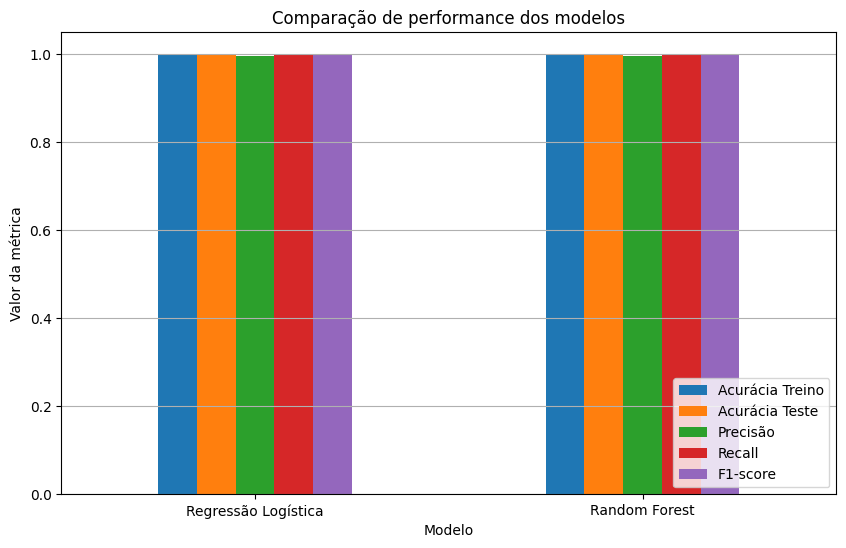

In [70]:
#6. AVALIAÇÃO INICIAL DOS MODELOS
#acuracia, precisao, recall, f1-score
#os dois modelos tiveram desempenho muito alto e praticamente igual no conjunto de teste,
#  com acurácia próxima de 99,8%.

# Faz um gráfico comparando as métricas dos modelos
resultados_df.set_index("Modelo")[[
    "Acurácia Treino",
    "Acurácia Teste",
    "Precisão",
    "Recall",
    "F1-score"
]].plot(kind="bar", figsize=(10, 6))

plt.title("Comparação de performance dos modelos")
plt.ylabel("Valor da métrica")
plt.xlabel("Modelo")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")

plt.show()

In [71]:
#6. OVERFITTING

# Calcula a diferença entre acurácia de treino e teste
# Diferença muito grande pode indicar overfitting

resultados_df["Diferença Treino-Teste"] = (
    resultados_df["Acurácia Treino"] - resultados_df["Acurácia Teste"]
)

resultados_df

,Modelo,Acurácia Treino,Acurácia Teste,Precisão,Recall,F1-score,Diferença Treino-Teste
0,Regressão Logística,0.998727,0.998042,0.996805,0.999199,0.998001,0.000685
1,Random Forest,0.999511,0.998042,0.996805,0.999199,0.998001,0.001468


In [72]:
#da celula anterior:

#pouca diferença: nao eh provavel de ter ocorrido overfitting

In [73]:
#7. VALIDAÇÃO CRUZADA

#implementa cross-validation com 5 divisões
# o modelo treina em 4 partes e testa em 1, repetindo isso 5 vezes
# ajuda a verificar se o desempenho é estável

resultados_cv = []

for nome, modelo in modelos.items():    
    scores = cross_val_score(
        modelo,
        x_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )
    
    resultados_cv.append({
        "Modelo": nome,
        "Acurácia média CV": scores.mean(),
        "Desvio padrão CV": scores.std()
    })

resultados_cv_df = pd.DataFrame(resultados_cv)

resultados_cv_df

,Modelo,Acurácia média CV,Desvio padrão CV
0,Regressão Logística,0.998434,0.001215
1,Random Forest,0.997846,0.001299


In [74]:
#da celula anterior:
# os resultados da validação cruzada foram muito próximos aos resultados do teste,
#  indicando estabilidade dos modelos

In [75]:
#8. VALIDAÇÃO FINAL

# Avalia os modelos no conjunto de validação final

resultados_validacao = []

for nome, modelo in modelos.items():
    
    # Treina novamente o modelo com o conjunto de treino
    modelo.fit(x_train, y_train)
    
    # Faz previsões no conjunto de validação
    y_pred_validacao = modelo.predict(x_validacao)
    
    # Calcula métricas na validação
    acc_validacao = accuracy_score(y_validacao, y_pred_validacao)
    precision_validacao = precision_score(y_validacao, y_pred_validacao)
    recall_validacao = recall_score(y_validacao, y_pred_validacao)
    f1_validacao = f1_score(y_validacao, y_pred_validacao)
    
    resultados_validacao.append({
        "Modelo": nome,
        "Acurácia Validação": acc_validacao,
        "Precisão Validação": precision_validacao,
        "Recall Validação": recall_validacao,
        "F1-score Validação": f1_validacao
    })

resultados_validacao_df = pd.DataFrame(resultados_validacao)

resultados_validacao_df

,Modelo,Acurácia Validação,Precisão Validação,Recall Validação,F1-score Validação
0,Regressão Logística,0.997782,0.997280,0.998185,0.997732
1,Random Forest,0.997338,0.997278,0.997278,0.997278


In [76]:
#9. HYPERPARAMETER TUNING
#GridSearchCV para testar combinações de hiperparâmetros
#  e encontrar a melhor configuração para cada modelo

# Implementa Hyperparameter Tuning com GridSearchCV
# O objetivo é testar diferentes combinações de hiperparâmetros
# e encontrar a configuração com melhor desempenho para cada modelo
parametros = {
    "Regressão Logística": {
        "modelo__C": [0.01, 0.1, 1, 10],
        "modelo__solver": ["lbfgs", "liblinear"]
    },
    
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10, 20],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2]
    }
}

resultados_tuning = []
melhores_modelos = {}

for nome, modelo in modelos.items():
    
    grid = GridSearchCV(
        estimator=modelo,
        param_grid=parametros[nome],
        cv=5,
        scoring="accuracy",
        n_jobs=1
    )
    
    # Treina várias combinações de hiperparâmetros usando validação cruzada
    grid.fit(x_train, y_train)
    
    # Salva o melhor modelo encontrado
    melhores_modelos[nome] = grid.best_estimator_
    
    # Avalia o melhor modelo no conjunto de teste
    y_pred_teste = grid.best_estimator_.predict(x_test)
    
    acc_teste = accuracy_score(y_test, y_pred_teste)
    precision_teste = precision_score(y_test, y_pred_teste)
    recall_teste = recall_score(y_test, y_pred_teste)
    f1_teste = f1_score(y_test, y_pred_teste)
    
    resultados_tuning.append({
        "Modelo": nome,
        "Melhores parâmetros": grid.best_params_,
        "Melhor acurácia CV": grid.best_score_,
        "Acurácia Teste": acc_teste,
        "Precisão Teste": precision_teste,
        "Recall Teste": recall_teste,
        "F1-score Teste": f1_teste
    })

resultados_tuning_df = pd.DataFrame(resultados_tuning)

resultados_tuning_df

,Modelo,Melhores parâmetros,Melhor acurácia CV,Acurácia Teste,Precisão Teste,Recall Teste,F1-score Teste
0,Regressão Logística,"{'modelo__C': 1, 'modelo__solver': 'liblinear'}",0.998532,0.997651,0.996010,0.999199,0.997602
1,Random Forest,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...",0.998532,0.998042,0.996805,0.999199,0.998001


In [77]:
#da celula anterior:

#melhores parametros encontrados:

#Regressão Logística:
# C = 1
# solver = liblinear

#Random Forest:
# max_depth = None
# min_samples_leaf = 2


#O tuning manteve o desempenho da Regressão Logística e melhorou levemente o
# Random Forest no conjunto de validação final, deixando os dois modelos com desempenho equivalente

In [34]:
# Avalia os melhores modelos encontrados pelo tuning no conjunto de validação final

resultados_validacao_tuning = []

for nome, modelo in melhores_modelos.items():
    
    y_pred_validacao = modelo.predict(x_validacao)
    
    acc_validacao = accuracy_score(y_validacao, y_pred_validacao)
    precision_validacao = precision_score(y_validacao, y_pred_validacao)
    recall_validacao = recall_score(y_validacao, y_pred_validacao)
    f1_validacao = f1_score(y_validacao, y_pred_validacao)
    
    resultados_validacao_tuning.append({
        "Modelo": nome,
        "Acurácia Validação após tuning": acc_validacao,
        "Precisão Validação após tuning": precision_validacao,
        "Recall Validação após tuning": recall_validacao,
        "F1-score Validação após tuning": f1_validacao
    })

resultados_validacao_tuning_df = pd.DataFrame(resultados_validacao_tuning)

resultados_validacao_tuning_df

,Modelo,Acurácia Validação após tuning,Precisão Validação após tuning,Recall Validação após tuning,F1-score Validação após tuning
0,Regressão Logística,0.997782,0.99728,0.998185,0.997732
1,Random Forest,0.997782,0.99728,0.998185,0.997732


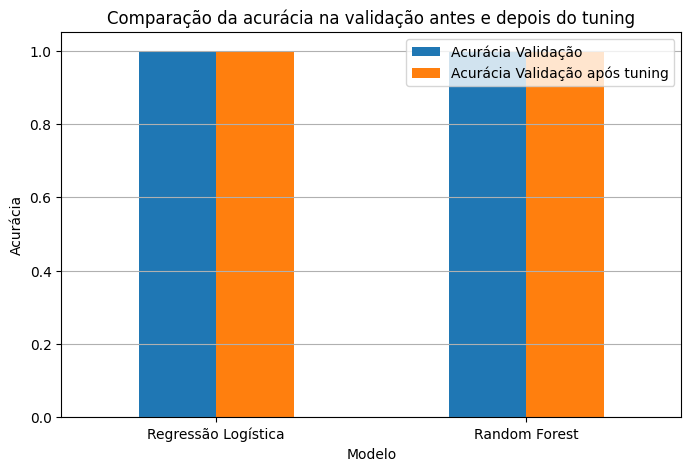

,Modelo,Acurácia Validação,Acurácia Validação após tuning
0,Regressão Logística,0.997782,0.997782
1,Random Forest,0.997338,0.997782


In [35]:
# Compara a acurácia no conjunto de validação antes e depois do tuning

comparacao_tuning = resultados_validacao_df[[
    "Modelo",
    "Acurácia Validação"
]].merge(
    resultados_validacao_tuning_df[[
        "Modelo",
        "Acurácia Validação após tuning"
    ]],
    on="Modelo"
)

comparacao_tuning.set_index("Modelo").plot(kind="bar", figsize=(8, 5))

plt.title("Comparação da acurácia na validação antes e depois do tuning")
plt.ylabel("Acurácia")
plt.xlabel("Modelo")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

comparacao_tuning

In [36]:
# Avalia os melhores modelos encontrados pelo tuning no conjunto de validação final

resultados_validacao_tuning = []

for nome, modelo in melhores_modelos.items():
    
    # Faz previsões no conjunto de validação final
    y_pred_validacao = modelo.predict(x_validacao)
    
    # Calcula métricas na validação final
    acc_validacao = accuracy_score(y_validacao, y_pred_validacao)
    precision_validacao = precision_score(y_validacao, y_pred_validacao)
    recall_validacao = recall_score(y_validacao, y_pred_validacao)
    f1_validacao = f1_score(y_validacao, y_pred_validacao)
    
    resultados_validacao_tuning.append({
        "Modelo": nome,
        "Acurácia Validação após tuning": acc_validacao,
        "Precisão Validação após tuning": precision_validacao,
        "Recall Validação após tuning": recall_validacao,
        "F1-score Validação após tuning": f1_validacao
    })

resultados_validacao_tuning_df = pd.DataFrame(resultados_validacao_tuning)

resultados_validacao_tuning_df

,Modelo,Acurácia Validação após tuning,Precisão Validação após tuning,Recall Validação após tuning,F1-score Validação após tuning
0,Regressão Logística,0.997782,0.99728,0.998185,0.997732
1,Random Forest,0.997782,0.99728,0.998185,0.997732


In [37]:
# Compara os resultados no conjunto de validação antes e depois do tuning

comparacao_tuning = resultados_validacao_df[[
    "Modelo",
    "Acurácia Validação"
]].merge(
    resultados_validacao_tuning_df[[
        "Modelo",
        "Acurácia Validação após tuning"
    ]],
    on="Modelo"
)

comparacao_tuning

,Modelo,Acurácia Validação,Acurácia Validação após tuning
0,Regressão Logística,0.997782,0.997782
1,Random Forest,0.997338,0.997782


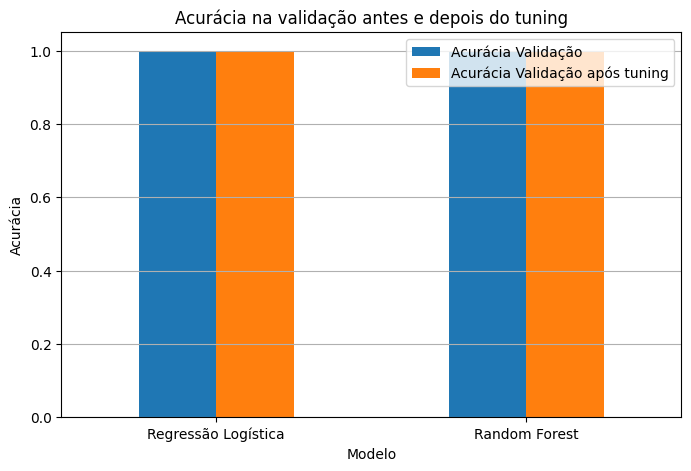

In [40]:
# Gráfico comparando a acurácia antes e depois do tuning

comparacao_tuning.set_index("Modelo").plot(kind="bar", figsize=(8, 5))

plt.title("Acurácia na validação antes e depois do tuning")
plt.ylabel("Acurácia")
plt.xlabel("Modelo")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

In [39]:
#o que acho que pode ter ocorrido:
#  mesmo apos todos ajustes, pode haver uma variavel que "entrega" os dados
#  vazamento de dados 

In [ ]:
#10. BOXPLOT DA DISTRIBUIÇÃO DE ACURÁCIA (VALIDAÇÃO CRUZADA)

#a validação cruzada armazenou só a média e o desvio padrão dos 5 folds
#aqui os 5 valores de cada fold sao guardados pra poder ver a distribuição inteira, nao só a media
#isso mostra se o desempenho é estável entre as divisões dos dados (e nao so "sorte" numa divisao especifica)

In [79]:
# Dicionário para guardar os scores de cada fold (nao so a media, como antes)
scores_por_fold = {}

for nome, modelo in modelos.items():
    scores = cross_val_score(
        modelo,
        x_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )
    # guarda o array completo com os 5 valores (um por fold)
    scores_por_fold[nome] = scores

# confere os valores guardados
for nome, scores in scores_por_fold.items():
    print(nome, "->", scores)

Regressão Logística -> [0.99902153 0.99951052 0.99853157 0.99608419 0.99902105]
Random Forest -> [0.99853229 0.99951052 0.99853157 0.99657367 0.99608419]


/tmp/ipykernel_229610/4214950583.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


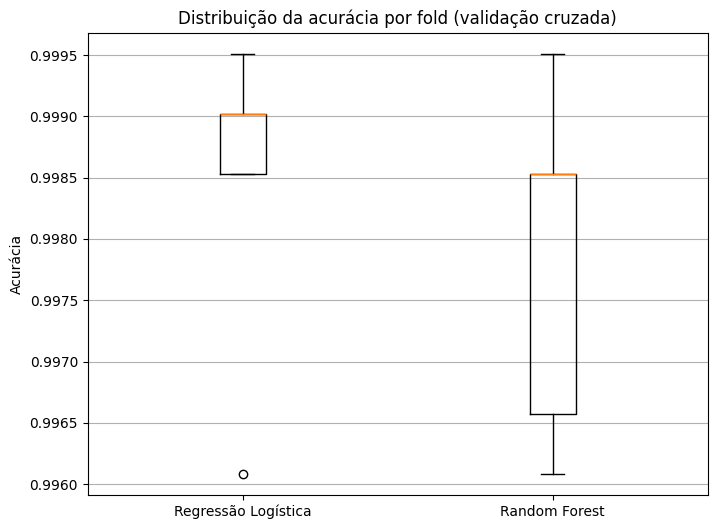

In [85]:
# Monta o boxplot comparando a distribuicao de acuracia dos 5 folds entre os modelos

plt.figure(figsize=(8, 6))
plt.boxplot(
    scores_por_fold.values(),
    labels=scores_por_fold.keys()
)

plt.title("Distribuição da acurácia por fold (validação cruzada)")
plt.ylabel("Acurácia")
plt.grid(axis="y")
plt.show()

#se a caixa for bem "achatada" (pouca variacao), o modelo é estavel entre os folds
#pontos fora da caixa (outliers) indicariam algum fold com resultado bem diferente dos outros

In [ ]:
#interpretacao do grafico anterior:

#todos valores de acurácia estao acima de 99%, similares
#indica que nao foi "sorte" de um dos folds, o modelo realmente tem bom desempenho
#ponto fora da caixa na regressao logistica nao necessariamente quer dizer que ha muita mudança (?)

In [92]:
#11. FEATURE IMPORTANCE (RANDOM FOREST)

#objetivo: ver quais variaveis mais influenciam a decisao do modelo
#isso ajuda a investigar a hipotese de vazamento de dados:
# se uma variavel concentrar a maior parte da importancia, é forte candidata a estar
# "entregando" a resposta (ex: um exame que só é feito depois do diagnostico)

#uso o melhor Random Forest encontrado no tuning
#a Regressao Logistica nao entra aqui pq ela nao tem .feature_importances_ (ela tem .coef_, que é outra coisa)

In [87]:
# Pega o melhor Random Forest (encontrado no GridSearchCV)
melhor_rf = melhores_modelos["Random Forest"]

# Extrai a importancia de cada variavel
importancias = melhor_rf.feature_importances_

# Junta o nome da variavel com a importancia dela numa tabela
importancia_df = pd.DataFrame({
    "Variável": x_train.columns,
    "Importância": importancias
})

# Ordena da mais importante pra menos importante
importancia_df = importancia_df.sort_values("Importância", ascending=False)

importancia_df

,Variável,Importância
14,Glóbulos rojos_normal,0.419331
15,Células de pus_normal,0.370683
18,Apetito_bueno,0.117501
4,Azúcar en orina,0.051585
5,Glucosa en sangre aleatoria,0.016353
3,Albúmina en orina,0.005232
7,Creatinina sérica,0.003509
13,Recuento de glóbulos rojos,0.003170
11,Volumen corpuscular empaquetado,0.003051
6,Urea en sangre,0.003037


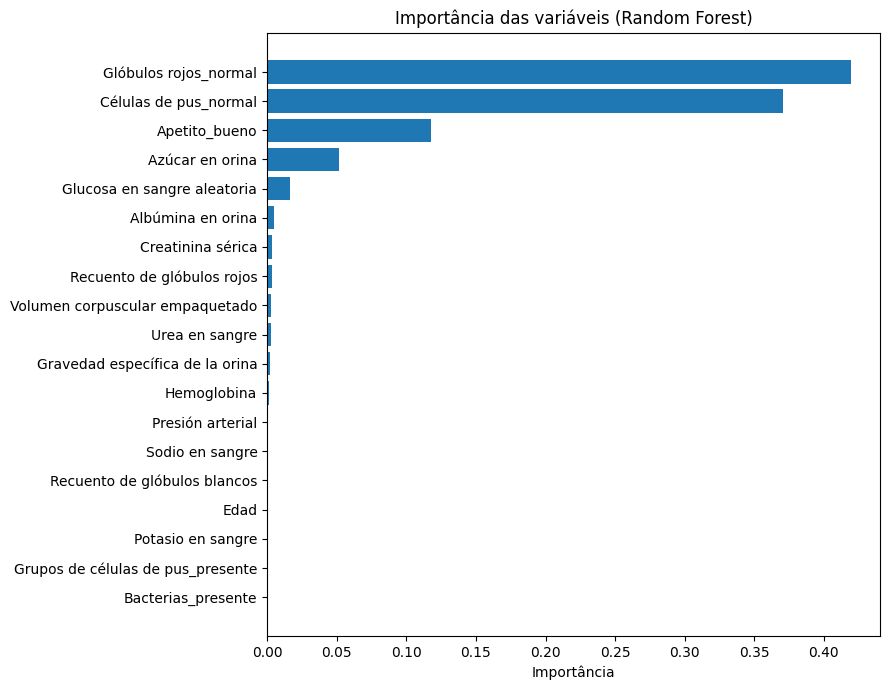

In [83]:
# Grafico de barras horizontal com a importancia de cada variavel
# (horizontal fica mais legivel pq os nomes das colunas sao longos)

plt.figure(figsize=(9, 7))
plt.barh(
    importancia_df["Variável"],
    importancia_df["Importância"]
)

plt.gca().invert_yaxis()  # deixa a variavel mais importante no topo
plt.title("Importância das variáveis (Random Forest)")
plt.xlabel("Importância")
plt.tight_layout()
plt.show()

#se uma variavel estiver muito destacada das outras, é sinal de alerta pra vazamento de dados
#se a importancia estiver bem distribuida entre varias variaveis, isso pesa contra a hipotese de vazamento

In [ ]:
#interpretando grafico anterior:

#globulos vermelho + globulos de pus + apetite = 91% da decisao do modelo
#provavel vazamento de dados (?)

In [93]:
#reduz o numero de features: mantem so as top N mais importantes
# e compara a acuracia do modelo reduzido com a do modelo completo

top_n = 3
top_features = importancia_df["Variável"].head(top_n).tolist()

print(f"Top {top_n} variáveis mais importantes:")
print(top_features)

# recorta treino e teste so com essas colunas
x_train_reduzido = x_train[top_features]
x_test_reduzido = x_test[top_features]

# treina um novo Random Forest so com as features reduzidas
rf_reduzido = RandomForestClassifier(random_state=42)
rf_reduzido.fit(x_train_reduzido, y_train)

y_pred_reduzido = rf_reduzido.predict(x_test_reduzido)
acc_reduzido = accuracy_score(y_test, y_pred_reduzido)

# acuracia do modelo completo (todas as variaveis), pra comparar
acc_completo = accuracy_score(y_test, melhor_rf.predict(x_test))

print(f"\nAcurácia com todas as {x_train.shape[1]} variáveis:", acc_completo)
print(f"Acurácia com apenas {top_n} variáveis:", acc_reduzido)

#se a acuracia reduzida ficar proxima da completa, o modelo nao precisava de todas as 19 variaveis
#isso simplifica o modelo sem perder desempenho

Top 3 variáveis mais importantes:
['Glóbulos rojos_normal', 'Células de pus_normal', 'Apetito_bueno']

Acurácia com todas as 19 variáveis: 0.9980422866092404
Acurácia com apenas 3 variáveis: 0.9980422866092404


In [94]:
#random forest rodado novamente com as 3 variaveis mais importantes
#a acuracia permanece praticamente a mesma, ou seja, provavel vazamento de dados

In [ ]:
#12. PCA - VISUALIZAÇÃO EM 2D

#objetivo: reduzir as 19 variaveis a 2 componentes principais pra poder visualizar os dados num grafico
#diferente do feature importance, aqui nao se escolhe variaveis originais - o PCA cria variaveis novas
# que sao combinacoes das originais, ordenadas por quanta informacao (variancia) cada uma capta

#PCA é sensivel a escala, entao preciso padronizar os dados antes (igual fiz na Regressao Logistica)

#a ideia aqui é ver se as duas classes ja aparecem separadas visualmente
# isso ajudaria a explicar a acuracia alta sem precisar necessariamente de vazamento de dados

In [98]:
from sklearn.decomposition import PCA

# Padroniza os dados antes do PCA (mesma logica do StandardScaler usado na Regressao Logistica)
scaler_pca = StandardScaler()
x_padronizado = scaler_pca.fit_transform(x)

# Aplica PCA reduzindo as 19 variaveis para 2 componentes principais
pca = PCA(n_components=2)
componentes = pca.fit_transform(x_padronizado)

# Confere quanta variancia (informacao) cada componente capturou
print("Variância explicada por componente:", pca.explained_variance_ratio_)
print("Variância total explicada pelos 2 componentes:", pca.explained_variance_ratio_.sum())

Variância explicada por componente: [0.32936718 0.14827523]
Variância total explicada pelos 2 componentes: 0.47764240836101085


In [99]:
#dos resultados anteriores:

#componente principal 1: 32,9%
#componente principal 2: 14,8%
# componente 1 + 2 = 47,8%

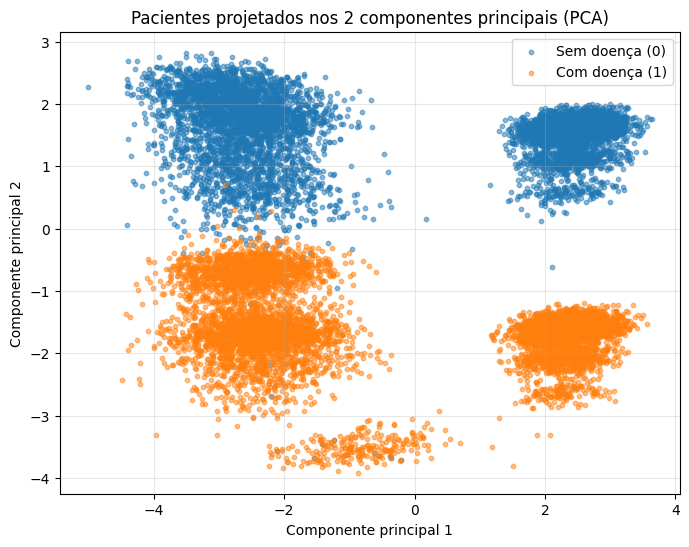

In [90]:
# Plota os pacientes no espaco dos 2 componentes principais, coloridos pela classe

plt.figure(figsize=(8, 6))
plt.scatter(
    componentes[y == 0, 0], componentes[y == 0, 1],
    label="Sem doença (0)", alpha=0.5, s=10
)
plt.scatter(
    componentes[y == 1, 0], componentes[y == 1, 1],
    label="Com doença (1)", alpha=0.5, s=10
)

plt.title("Pacientes projetados nos 2 componentes principais (PCA)")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#se as duas cores aparecerem bem separadas em "nuvens" distintas,
# é evidencia visual de que as classes ja sao naturalmente bem separaveis
#se aparecerem misturadas, a separabilidade alta do modelo nao vem so da geometria dos dados em si

In [100]:
#interpretando o grafico:

#azul: sem doença
#laranja: com doença

#nuvens bem separadas, problema facil de definir (?)

In [102]:
#resumo desses 3 pontos, pra amarrar com a hipotese de vazamento (celula 31):

#- boxplot: mostra se o desempenho é estavel entre os folds (nao foi so sorte numa divisao)
#- feature importance: investiga se alguma variavel especifica concentra a decisao do modelo
#- PCA: mostra visualmente se as classes ja nascem separadas no espaco das variaveis

#juntos, esses 3 pontos ajudam a entender melhor PORQUE a acuracia ficou tao alta (99,8%)

In [103]:
###########################

In [115]:
######### 1. metrica MCC: mathews correlation coefficient
# varia de +1 a -1
# +1: classificação perfeita
# 0: o modelo é um chute aleatorio
# -1: classificação completamente errada

# pq escolher mcc?
# While accuracy can be highly misleading when one class dominates the dataset,
# the MCC treats both classes symmetrically. Unlike the F1 score,
# which completely ignores True Negatives, the MCC accounts for them,
# providing a much more robust and realistic assessment of a model's true capabilities

In [106]:
from sklearn.metrics import matthews_corrcoef

# calcula o MCC de cada modelo no conjunto de teste
mcc_resultados = {}

for nome, modelo in modelos.items():
    y_pred = modelo.predict(x_test)
    mcc = matthews_corrcoef(y_test, y_pred)
    mcc_resultados[nome] = mcc

for nome, mcc in mcc_resultados.items():
    print(f"{nome} -> MCC: {mcc:.4f}")

Regressão Logística -> MCC: 0.9961
Random Forest -> MCC: 0.9961


In [107]:
#resultados da ultima celula:
# proximos a +1, ou seja,
# alto poder preditivo

In [126]:
######### 2. PCA COLORIDO COM AS TOP FEATURES

top_3_features = importancia_df["Variável"].head(3).tolist()
print("Top 3 variáveis usadas para colorir:", top_3_features)

Top 3 variáveis usadas para colorir: ['Glóbulos rojos_normal', 'Células de pus_normal', 'Apetito_bueno']


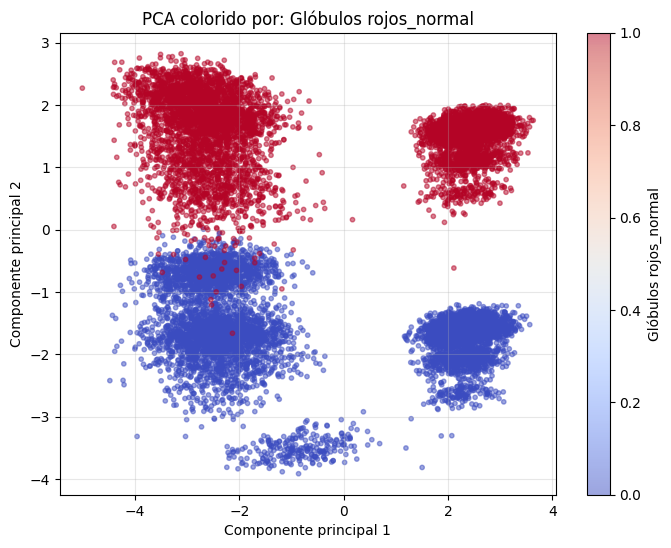

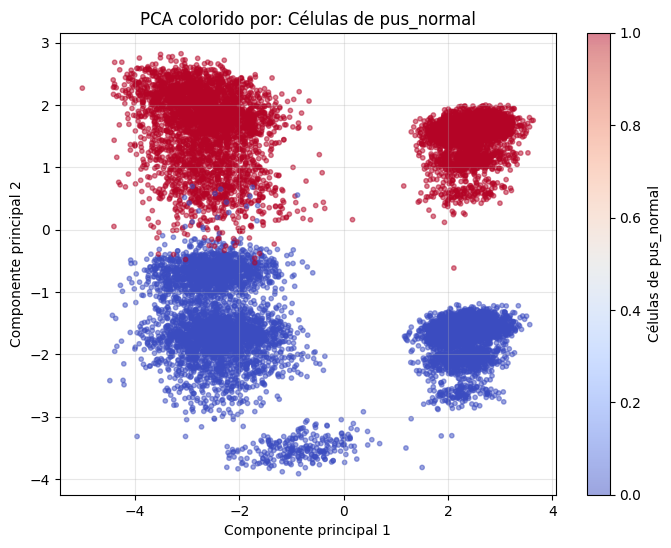

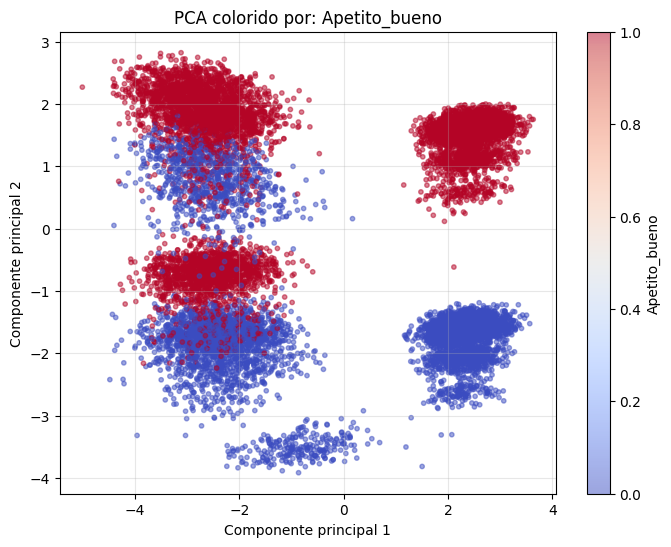

In [112]:
# gera uma figura para cada uma das top 3 variaveis

for feature in top_3_features:
    plt.figure(figsize=(8, 6))
    
    scatter = plt.scatter(
        componentes[:, 0], componentes[:, 1],
        c=x[feature], cmap="coolwarm", alpha=0.5, s=10
    )
    
    plt.title(f"PCA colorido por: {feature}")
    plt.xlabel("Componente principal 1")
    plt.ylabel("Componente principal 2")
    plt.colorbar(scatter, label=feature)
    plt.grid(alpha=0.3)
    plt.show()

In [127]:
###### interpretacao dos graficos:
# os dois primeiros, globulos vermelho e celulas de pus sao parecidos
# = tem importancias parecidas de top features (41% e 37%)

# ja o apetite (11%) tem as nuvens mais sobrepostas
# = tem poder preditivo bem menor que as outras duas

In [128]:
######### 3. REAPLICAR OS MODELOS SEM AS TOP 2 FEATURES

#objetivo: remover as duas variaveis que somam ~69% do poder preditivo
# e rodar novamente o random forest

In [118]:
top_2_features = importancia_df["Variável"].head(2).tolist()
print("Variáveis removidas:", top_2_features)

# recorta treino e teste tirando essas 2 colunas
x_train_sem2 = x_train.drop(columns=top_2_features)
x_test_sem2 = x_test.drop(columns=top_2_features)

Variáveis removidas: ['Glóbulos rojos_normal', 'Células de pus_normal']


In [119]:
# retreina os dois modelos do zero, so com as variaveis restantes (17 de 19)

modelos_sem2 = {
    "Regressão Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(random_state=42)
}

resultados_sem2 = []

for nome, modelo in modelos_sem2.items():
    modelo.fit(x_train_sem2, y_train)
    y_pred = modelo.predict(x_test_sem2)

    resultados_sem2.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precisão": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

resultados_sem2_df = pd.DataFrame(resultados_sem2)
resultados_sem2_df

,Modelo,Acurácia,Precisão,Recall,F1-score,MCC
0,Regressão Logística,0.920125,0.923763,0.911930,0.917808,0.840196
1,Random Forest,0.958496,0.926174,0.994396,0.959073,0.919468


In [123]:
# comparação lado a lado:
# modelo completo (19 variaveis) vs modelo sem as 2 top features (17 variaveis)

comparacao_sem2 = pd.DataFrame({
    "Modelo": ["Regressão Logística", "Random Forest"],
    "Acurácia (completo)": [
        accuracy_score(y_test, modelos["Regressão Logística"].predict(x_test)),
        accuracy_score(y_test, melhor_rf.predict(x_test))
    ],
    "Acurácia (sem top 2)": resultados_sem2_df["Acurácia"].tolist(),
    "MCC (completo)": [
        matthews_corrcoef(y_test, modelos["Regressão Logística"].predict(x_test)),
        matthews_corrcoef(y_test, melhor_rf.predict(x_test))
    ],
    "MCC (sem top 2)": resultados_sem2_df["MCC"].tolist()
})

comparacao_sem2

,Modelo,Acurácia (completo),Acurácia (sem top 2),MCC (completo),MCC (sem top 2)
0,Regressão Logística,0.998042,0.920125,0.996086,0.840196
1,Random Forest,0.998042,0.958496,0.996086,0.919468


In [124]:
###interpretação do resultado anterior:

#acurácia:
# regressao logistica: caiu de 99.8% para 92%
# random forest: caiu de 99,8% para 95,8%
# pouca queda, nao ha muita alteração na predição

#mcc:
# regreassao logistica: caiu de 99,6% para 84%
# random forest: caiu de 99,6% para 91,99%

#se fosse muito vazamento de dados, as metricas deveriam diminuir mais (?)

In [125]:
######### 4. CORRELAÇÃO E PREVALÊNCIA ENTRE Y E AS 2 TOP FEATURES

#objetivo: checar se essas 2 variaveis, sozinhas (sem nenhum modelo), ja "andam junto" com o diagnostico
#prevalencia = taxa de doença dentro de cada grupo da variavel (0 e 1)
#correlacao (coeficiente phi) = a mesma formula do MCC, mas comparando a variavel direto com y,
# sem passar por nenhum modelo treinado

for feature in top_2_features:
    print(f"\n{'='*50}")
    print(f"VARIÁVEL: {feature}")
    print('='*50)

    # tabela cruzada: quantos pacientes em cada combinação (variavel x diagnostico)
    tabela_contagem = pd.crosstab(x[feature], y)
    print("\nContagem de pacientes:")
    print(tabela_contagem)

    # mesma tabela, mas em % de doença DENTRO de cada grupo da variavel (prevalencia)
    tabela_prevalencia = pd.crosstab(x[feature], y, normalize="index") * 100
    tabela_prevalencia.columns = ["% Sem doença", "% Com doença"]
    print("\nPrevalência (% dentro de cada grupo):")
    print(tabela_prevalencia.round(1))

    # correlacao (coeficiente phi, calculado com a mesma funcao do MCC)
    phi = matthews_corrcoef(y, x[feature])
    print(f"\nCorrelação (phi) entre '{feature}' e o diagnóstico: {phi:.4f}")


VARIÁVEL: Glóbulos rojos_normal

Contagem de pacientes:
Insuficiencia renal crónica     0     1
Glóbulos rojos_normal                  
0.0                            16  7337
1.0                          7662     9

Prevalência (% dentro de cada grupo):
                       % Sem doença  % Com doença
Glóbulos rojos_normal                            
0.0                             0.2          99.8
1.0                            99.9           0.1

Correlação (phi) entre 'Glóbulos rojos_normal' e o diagnóstico: -0.9967

VARIÁVEL: Células de pus_normal

Contagem de pacientes:
Insuficiencia renal crónica     0     1
Células de pus_normal                  
0.0                            42  7346
1.0                          7636     0

Prevalência (% dentro de cada grupo):
                       % Sem doença  % Com doença
Células de pus_normal                            
0.0                             0.6          99.4
1.0                           100.0           0.0

Correlação (ph

In [ ]:
####################################################

#construcao de novos modelos, treinado a partir das x top features
# iniciando em 1, 2, 3, ..., 

#1. Glóbulos rojos_normal	0.419331
#2.	Células de pus_normal	0.370683
#3.	Apetito_bueno	0.117501
#4.	Azúcar en orina	0.051585
#5.	Glucosa en sangre aleatoria	0.016353
#6.	Albúmina en orina	0.005232
#7.	Creatinina sérica	0.003509
#8.	Recuento de glóbulos rojos	0.003170
#9.	Volumen corpuscular empaquetado	0.003051
#10.Urea en sangre	0.003037
#11.Gravedad específica de la orina	0.002416
#12.Hemoglobina	0.001043
#2.	Presión arterial	0.000982
#2.	Sodio en sangre	0.000589
#2.	Recuento de glóbulos blancos	0.000540
#2.	Edad	0.000442
#2.	Potasio en sangre	0.000370
#2.	Grupos de células de pus_presente	0.000130
#2.	Bacterias_presente	0.000036


####################################################

In [ ]:
######### 5. MCC vs NUMERO DE FEATURES (top-N, N de 1 a 19)
# reaproveita o ranking de importancia_df, que ja esta ordenado do mais pro menos importante

In [ ]:
resultados_top_n = []

for n in range(1, len(importancia_df) + 1):
    # pega as top-N variaveis do ranking
    features_n = importancia_df["Variável"].head(n).tolist()

    x_train_n = x_train[features_n]
    x_test_n = x_test[features_n]

    # recria os dois modelos do zero a cada rodada (senao ficariam "treinados" com o N anterior)
    modelos_n = {
        "Regressão Logística": Pipeline([
            ("scaler", StandardScaler()),
            ("modelo", LogisticRegression(max_iter=1000, random_state=42))
        ]),
        "Random Forest": RandomForestClassifier(random_state=42)
    }

    for nome, modelo in modelos_n.items():
        modelo.fit(x_train_n, y_train)
        y_pred_n = modelo.predict(x_test_n)
        mcc_n = matthews_corrcoef(y_test, y_pred_n)

        resultados_top_n.append({
            "Número de features": n,
            "Modelo": nome,
            "MCC": mcc_n
        })

resultados_top_n_df = pd.DataFrame(resultados_top_n)
resultados_top_n_df

In [ ]:
# grafico de linha: MCC em funcao do numero de features usadas (top-N)
# escala do eixo Y de 0 a 1 pra mostrar a variacao real (~0,0008) sem exagero visual

plt.figure(figsize=(10, 6))

for nome in resultados_top_n_df["Modelo"].unique():
    subset = resultados_top_n_df[resultados_top_n_df["Modelo"] == nome]
    plt.plot(subset["Número de features"], subset["MCC"], marker="o", label=nome)

plt.title("MCC em função do número de features (top-N por importância)")
plt.xlabel("Número de features utilizadas (top-N, do ranking de importância)")
plt.ylabel("MCC")
plt.xticks(range(1, len(importancia_df) + 1))
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
#interpretacao do grafico anterior:

#com apenas 1 feature (Glóbulos rojos_normal) o MCC ja eh 0,996, igual ao de 19 features
#os "mergulhos" em N=5 (RF) e N=15 (RL) sao variacao de ~0,0008 (1-2 pacientes), ruido e nao padrao real
#curva praticamente reta desde N=1: 1 variavel ja resolve o problema, coerente com o phi = -0,997

In [ ]:
######### 6. MCC vs NUMERO DE FEATURES, SEM AS 2 TOP FEATURES

# objetivo: excluindo Glóbulos rojos_normal e Células de pus_normal,
# o restante das variaveis (do 3o lugar em diante) tambem satura rapido ou precisa de mais features?

# remove as 2 top features do ranking, mantendo a ordem das demais
importancia_sem_top2 = importancia_df[~importancia_df["Variável"].isin(top_2_features)].reset_index(drop=True)

print("Ranking sem as 2 top features:")
importancia_sem_top2

In [ ]:
resultados_top_n_sem2 = []

for n in range(1, len(importancia_sem_top2) + 1):
    # pega as top-N variaveis do ranking SEM as 2 primeiras
    features_n = importancia_sem_top2["Variável"].head(n).tolist()

    x_train_n = x_train[features_n]
    x_test_n = x_test[features_n]

    modelos_n = {
        "Regressão Logística": Pipeline([
            ("scaler", StandardScaler()),
            ("modelo", LogisticRegression(max_iter=1000, random_state=42))
        ]),
        "Random Forest": RandomForestClassifier(random_state=42)
    }

    for nome, modelo in modelos_n.items():
        modelo.fit(x_train_n, y_train)
        y_pred_n = modelo.predict(x_test_n)
        mcc_n = matthews_corrcoef(y_test, y_pred_n)

        resultados_top_n_sem2.append({
            "Número de features": n,
            "Modelo": nome,
            "MCC": mcc_n
        })

resultados_top_n_sem2_df = pd.DataFrame(resultados_top_n_sem2)
resultados_top_n_sem2_df

In [ ]:
# grafico de linha: MCC em funcao do numero de features usadas (top-N, sem as 2 top originais)

plt.figure(figsize=(10, 6))

for nome in resultados_top_n_sem2_df["Modelo"].unique():
    subset = resultados_top_n_sem2_df[resultados_top_n_sem2_df["Modelo"] == nome]
    plt.plot(subset["Número de features"], subset["MCC"], marker="o", label=nome)

plt.title("MCC em função do número de features (top-N, sem as 2 top originais)")
plt.xlabel("Número de features utilizadas (top-N, ranking sem as 2 top originais)")
plt.ylabel("MCC")
plt.xticks(range(1, len(importancia_sem_top2) + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
#interpretacao do grafico anterior:

#sem as 2 top features nenhum modelo satura em N=1 (MCC ~0,68 so com Apetito_bueno)
#random forest: salto grande de N=1 para N=2 (0,68 -> 0,89) e platô em ~0,91 a partir de N=3-5
#regressao logistica: salto em N=3 (0,72 -> 0,83) e platô em ~0,84
#a partir de N=3 os ganhos sao pequenos e oscilam (ruido), entao N=3 eh o minimo que mantem desempenho estavel:
#  Apetito_bueno, Azúcar en orina, Glucosa en sangre aleatoria
#custo de remover as 2 top features: MCC cai de ~0,996 para ~0,90 (RF) / ~0,83 (RL)
#o sinal das 17 variaveis restantes eh real, porem mais distribuido e mais fraco